In [1]:
!pip install -q condacolab
import condacolab
condacolab.install()
!conda install -c conda-forge pymeep -y
!conda install dnachun::torchviz

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

📢 Announcement 📢
condacolab==0.2 will be released soon! Try it with:

    !pip install -q https://github.com/conda-incubator/condacolab/archive/main.zip
    import condacolab
    condacolab.install()

0.2.x introduces a new installation method based on Pixi, with customizable Python versions.
This may be breaking for your workflow. If that's the case, please report it at
https://github.com/conda-incubator/condacolab and pin your `pip install` command to:

    !pip install -q 'condacolab==0.1.*'

✨🍰✨ Everything looks OK!
Channels:
 - conda-forge
Platform: linux-64
Solving environment: | / done


==> WARNING: A newer version of conda exists. <==
    current version: 26.7.3
    latest version: 26.10.0

Please update conda by running

    $ conda update -n base -c conda-forge conda



# All requested packages already installed.

Channels:
 - conda-forge
 - d

### Paso 1: Descarga del conjunto de datos
En este paso, descargamos el archivo `filter_dataset.npz` que contiene los datos de entrenamiento previamente calculados (curvas de parámetros S11 de dispersión para diferentes dimensiones físicas de la guía de ondas corrugada). El uso de un conjunto de datos precalculado ahorra horas de simulaciones físicas complejas.

In [1]:
!wget https://github.com/saint-germain/physics-informed-nn/raw/refs/heads/main/filter_dataset.npz

--2026-11-18 02:50:04--  https://github.com/saint-germain/physics-informed-nn/raw/refs/heads/main/filter_dataset.npz
Resolving github.com (github.com)... 140.82.114.3
Connecting to github.com (github.com)|140.82.114.3|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/saint-germain/physics-informed-nn/refs/heads/main/filter_dataset.npz [following]
--2026-11-18 02:50:04--  https://raw.githubusercontent.com/saint-germain/physics-informed-nn/refs/heads/main/filter_dataset.npz
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 15730365 (15M) [application/octet-stream]
Saving to: ‘filter_dataset.npz’

filter_dataset.npz  100%[===================>]  15.00M  53.7MB/s    in 0.3s    

2026-11-18 02:50:05 (53.

### Paso 2: Configuración global y funciones auxiliares para simulaciones físicas (MEEP)
En esta celda se configuran las propiedades fundamentales para las simulaciones electromagnéticas en 2D utilizando MEEP (MIT Electromagnetic Equation Propagation). Aquí definimos:
- Los límites de frecuencia de la banda W ($75\text{ a }110\text{ GHz}$).
- Los rangos y restricciones para las 7 variables geométricas que controlan la guía de ondas y sus irises/corrugaciones simétricas.
- Las funciones auxiliares para evaluar un diseño geométrico específico (`evaluate_single_sample`) y visualizar la geometría resultante o las respuestas de pérdidas de retorno ($S_{11}$).

In [4]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

import meep as mp
import numpy as np
import time
from joblib import Parallel, delayed
import matplotlib.pyplot as plt

# ==========================================
# 1. Global Setup
# ==========================================
c_mm = 299.792458
fcen = 110.0 / c_mm
df = 80.0 / c_mm
nfreq = 200
resolution = 40

# ==========================================
# 2. Prior Sampler (7-Parameter Symmetric)
# ==========================================
PRIOR_BOUNDS = {
    'a':           (2.50, 2.58),  # Locked near WR-10 standard
    'notch_width': (0.60, 1.40),  # Allowed iris thicknesses
    'h1':          (0.05, 0.25),  # Outer taper
    'h2':          (0.05, 0.25),  # Mid taper
    'h3':          (0.25, 0.45),  # Center pinch
    's1':          (1.70, 3.90),  # Expanded for 85-145 GHz passbands
    's2':          (1.70, 3.90)   # Expanded for 85-145 GHz passbands
}

# 2. Data Generation Prior (Dynamically unpacks the dictionary)
def sample_prior():
    """
    Samples a 7-parameter vector bounded strictly by PRIOR_BOUNDS.
    """
    a = np.random.uniform(*PRIOR_BOUNDS['a'])
    notch_width = np.random.uniform(*PRIOR_BOUNDS['notch_width'])
    h1 = np.random.uniform(*PRIOR_BOUNDS['h1'])
    h2 = np.random.uniform(*PRIOR_BOUNDS['h2'])
    h3 = np.random.uniform(*PRIOR_BOUNDS['h3'])
    s1 = np.random.uniform(*PRIOR_BOUNDS['s1'])
    s2 = np.random.uniform(*PRIOR_BOUNDS['s2'])

    return [a, notch_width, h1, h2, h3, s1, s2]

# ==========================================
# 3. 100% Self-Contained Worker Function
# ==========================================
def evaluate_single_sample(params):
    """
    Completely self-contained to guarantee zero cross-process pickling errors.
    Initializes MEEP, runs the normalization, runs the filter, and returns pure Python types.
    """
    # Hide MEEP output for cleaner parallel logging
    mp.verbosity(0)

    # Unpack the 7 parameters
    a, notch_width, h1, h2, h3, s1, s2 = params

    # Map the 3 heights symmetrically to the 5 notches
    heights = [h1, h2, h3, h2, h1]

    # Calculate absolute X positions symmetrically from a fixed starting point
    start_x = -4.0
    x_positions = [
        start_x,
        start_x + s1,
        start_x + s1 + s2,
        start_x + s1 + s2 + s2,
        start_x + s1 + s2 + s2 + s1
    ]

    cell_size = mp.Vector3(36, a, 0)
    pml_layers = [mp.PML(1.0, direction=mp.X)]
    symmetries = [mp.Mirror(mp.Y, phase=1)]

    sources = [mp.EigenModeSource(src=mp.GaussianSource(fcen, fwidth=df),
                                  center=mp.Vector3(-15, 0, 0),
                                  size=mp.Vector3(0, a, 0),
                                  eig_band=1,
                                  direction=mp.X)]

    refl_fr = mp.FluxRegion(center=mp.Vector3(-12, 0, 0), size=mp.Vector3(0, a, 0))
    tran_fr = mp.FluxRegion(center=mp.Vector3(12, 0, 0), size=mp.Vector3(0, a, 0))

    try:
        # 1. Normalization Run
        sim_norm = mp.Simulation(cell_size=cell_size, resolution=resolution, boundary_layers=pml_layers,
                                 sources=sources, symmetries=symmetries, geometry=[])
        refl_n = sim_norm.add_flux(fcen, df, nfreq, refl_fr)
        tran_n = sim_norm.add_flux(fcen, df, nfreq, tran_fr)
        sim_norm.run(until_after_sources=mp.stop_when_fields_decayed(50, mp.Ez, mp.Vector3(12, 0, 0), 1e-4))

        empty_refl_data = sim_norm.get_flux_data(refl_n)
        empty_tran_flux = mp.get_fluxes(tran_n)
        freqs = np.array(mp.get_flux_freqs(refl_n)) * c_mm

        # 2. Filter Geometry setup
        geometry_filter = []
        for i in range(5):
            h = heights[i]
            x_pos = x_positions[i]
            geometry_filter.append(mp.Block(size=mp.Vector3(notch_width, h, mp.inf),
                                            center=mp.Vector3(x_pos, a/2 - h/2, 0), material=mp.metal))
            geometry_filter.append(mp.Block(size=mp.Vector3(notch_width, h, mp.inf),
                                            center=mp.Vector3(x_pos, -a/2 + h/2, 0), material=mp.metal))

        # 3. Filter Run
        sim = mp.Simulation(cell_size=cell_size, resolution=resolution, boundary_layers=pml_layers,
                            sources=sources, symmetries=symmetries, geometry=geometry_filter)
        refl = sim.add_flux(fcen, df, nfreq, refl_fr)
        sim.load_minus_flux_data(refl, empty_refl_data)
        sim.run(until_after_sources=mp.stop_when_fields_decayed(50, mp.Ez, mp.Vector3(-12, 0, 0), 1e-4))

        S11 = -np.array(mp.get_fluxes(refl)) / np.array(empty_tran_flux)
        S11_dB = 10 * np.log10(np.clip(np.abs(S11), 1e-10, None))

        # 4. Quality Scoring
        mask = (freqs >= 75) & (freqs <= 110)
        if len(S11_dB[mask]) == 0:
            return params, S11_dB, freqs, False

        peak_s11 = np.max(S11_dB[mask])
        peak_freq = freqs[mask][np.argmax(S11_dB[mask])]
        is_valid = (peak_s11 > -5.0) and (abs(peak_freq - 90.0) < 15.0)

        return params, S11_dB, freqs, is_valid

    except Exception as e:
        return params, None, None, False

def visualize_s11(freqs, S11_dB):
    freqs_GHz = np.array(freqs).flatten() * c_mm
    S11_flat = np.array(S11_dB).flatten()

    plt.figure(figsize=(10, 6))
    plt.plot(freqs_GHz, S11_flat, label='S11 (Return Loss)', color='tab:blue', linewidth=2)
    plt.title("W-Band Corrugated Waveguide Filter")
    plt.xlabel("Frequency (GHz)")
    plt.ylabel("Magnitude (dB)")
    plt.xlim(freqs_GHz.min(), freqs_GHz.max())
    plt.ylim(-40, 5)
    plt.axhline(0, color='black', linewidth=0.5)
    plt.grid(True, alpha=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()

def visualize_geometry(params):
    """
    Constructs and visualizes the 2D waveguide geometry for a given parameter vector.
    """
    a, notch_width, h1, h2, h3, s1, s2 = params
    heights = [h1, h2, h3, h2, h1]

    start_x = -4.0
    x_positions = [
        start_x,
        start_x + s1,
        start_x + s1 + s2,
        start_x + s1 + s2 + s2,
        start_x + s1 + s2 + s2 + s1
    ]

    cell_size = mp.Vector3(36, a, 0)
    pml_layers = [mp.PML(1.0, direction=mp.X)]
    symmetries = [mp.Mirror(mp.Y, phase=1)]
    sources = [mp.EigenModeSource(src=mp.GaussianSource(fcen, fwidth=df),
                                  center=mp.Vector3(-15, 0, 0),
                                  size=mp.Vector3(0, a, 0),
                                  eig_band=1,
                                  direction=mp.X)]

    geometry_filter = []
    for i in range(5):
        h = heights[i]
        x_pos = x_positions[i]
        # Top block
        geometry_filter.append(mp.Block(size=mp.Vector3(notch_width, h, mp.inf),
                                        center=mp.Vector3(x_pos, a/2 - h/2, 0), material=mp.metal))
        # Bottom block
        geometry_filter.append(mp.Block(size=mp.Vector3(notch_width, h, mp.inf),
                                        center=mp.Vector3(x_pos, -a/2 + h/2, 0), material=mp.metal))

    sim = mp.Simulation(cell_size=cell_size,
                        resolution=resolution,
                        boundary_layers=pml_layers,
                        sources=sources,
                        symmetries=symmetries,
                        geometry=geometry_filter)

    sim.init_sim()
    fig, ax = plt.subplots(figsize=(12, 4))
    sim.plot2D(ax=ax)

    plt.title("2D H-Plane Cross-Section of Symmetric Tapered Filter")
    plt.xlabel("X coordinate (mm)")
    plt.ylabel("Y coordinate (mm)")
    plt.tight_layout()
    plt.show()

### Paso 3: Carga, verificación y visualización de muestras del conjunto de datos
Este código carga la base de datos descargada y separa las variables de entrada ($X$, que representan los parámetros geométricos) de los objetivos ($Y$, que son las respuestas espectrales $S_{11}$). A continuación, se grafica un ejemplo aleatorio para comprobar visualmente la correspondencia entre la estructura geométrica en 2D y su comportamiento electromagnético.

Loaded X shape: (10000, 7)
Loaded Y shape: (10000, 200)
Dataset Metadata: {'c_mm': 299.792458, 'num_samples': 10000, 'generation_time_sec': 37310.679731845856, 'parameter_format': '[a, notch_width, h1, h2, h3, s1, s2]'}


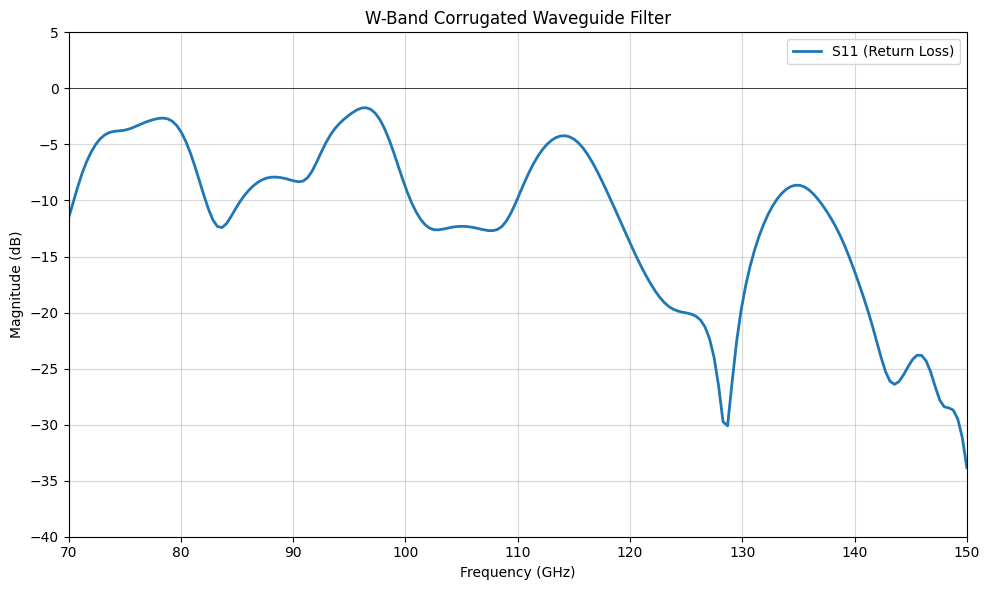

-----------
Initializing structure...
Padding y to even number of grid points.
Halving computational cell along direction y
time for choose_chunkdivision = 0.00196314 s
Working in 2D dimensions.
Computational cell is 36 x 2.525 x 0 with resolution 40
     block, center = (-4,1.18828,0)
          size (0.791326,0.159531,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (-1e+20,-1e+20,-1e+20)
     block, center = (-4,-1.18828,0)
          size (0.791326,0.159531,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (-1e+20,-1e+20,-1e+20)
     block, center = (-0.172771,1.23405,0)
          size (0.791326,0.0680022,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (-1e+20,-1e+20,-1e+20)
     block, center = (-0.172771,-1.23405,0)
          size (0.791326,0.0680022,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diago

MPB solved for frequency_1(0.366921,0,0) = 0.366921 after 10 iters


     block, center = (-4,1.18828,0)
          size (0.791326,0.159531,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (-1e+20,-1e+20,-1e+20)
     block, center = (-4,-1.18828,0)
          size (0.791326,0.159531,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (-1e+20,-1e+20,-1e+20)
     block, center = (-0.172771,1.23405,0)
          size (0.791326,0.0680022,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (-1e+20,-1e+20,-1e+20)
     block, center = (-0.172771,-1.23405,0)
          size (0.791326,0.0680022,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (-1e+20,-1e+20,-1e+20)
     block, center = (2.96983,1.11397,0)
          size (0.791326,0.308156,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (-1e+20,-1e+20,-1e+20)
     block, center = (2.969

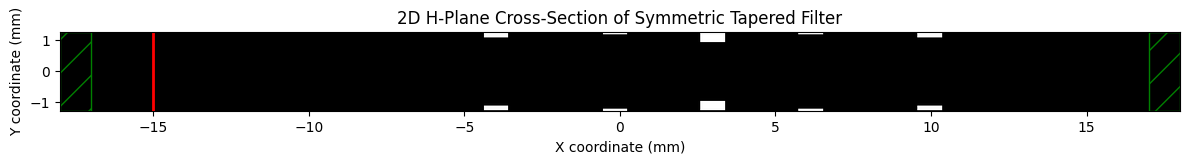

In [5]:

data = np.load(filename2, allow_pickle=True)

X = data["parameters"]
Y = data["s11_curves"]
freqs = data["frequencies"]
valid = data["valid_flags"]
meta = data["metadata"].item()

print("Loaded X shape:", X.shape)
print("Loaded Y shape:", Y.shape)
print("Dataset Metadata:", meta)
ix=1
p0=X[ix]
S11_dB=Y[ix]
visualize_s11(freqs/c_mm, S11_dB) # visualize takes freqs in sim units

visualize_geometry(p0)

### Paso 4: Preparación de datos y definición del modelo sustituto (Surrogate Model)
Para acelerar el proceso de diseño inverso sin recurrir a simulaciones costosas en tiempo real, entrenaremos una red neuronal como modelo sustituto. En esta sección:
- Dividimos los datos válidos en conjuntos de entrenamiento (80%), validación (10%) y prueba (10%).
- Normalizamos los parámetros geométricos utilizando `StandardScaler` para facilitar el entrenamiento.
- Definimos la arquitectura `BottleneckSurrogate`. Al forzar los datos a través de una capa de cuello de botella comprimida ($7 \to 32 \to 200$), obligamos a la red a generalizar las leyes de la física del electromagnetismo en lugar de memorizar las respuestas individuales.

In [6]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# ==========================================
# 1. Dataset & Dataloader
# ==========================================
class WaveguideDataset(Dataset):
    def __init__(self, X, Y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.Y = torch.tensor(Y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.Y[idx]

def load_and_preprocess(filename="w_band_filter_dataset_test.npz", batch_size=64):
    """
    Loads the MEEP dataset, filters for valid geometries, scales the features,
    and splits into 80/10/10 Train/Val/Test sets.
    """
    data = np.load(filename)
    X_raw = data["parameters"]
    Y_raw = data["s11_curves"]
    valid = data["valid_flags"]
    freqs = data["frequencies"]

    # Filter out geometries that failed the physics quality checks
    X_valid = X_raw[valid]
    Y_valid = Y_raw[valid]

    # Standardize the 7-parameter input space (critical for deep learning gradients)
    x_scaler = StandardScaler()
    X_scaled = x_scaler.fit_transform(X_valid)

    # Optional: Scale Y to [-1, 1] range if S11 drops extremely low, but raw dB works well for MSE
    # Y_scaler = StandardScaler()
    # Y_scaled = Y_scaler.fit_transform(Y_valid)

    # 80% Train, 20% Temp
    X_train, X_temp, Y_train, Y_temp = train_test_split(X_scaled, Y_valid, test_size=0.20, random_state=42)
    # Split Temp into 10% Val, 10% Test
    X_val, X_test, Y_val, Y_test = train_test_split(X_temp, Y_temp, test_size=0.50, random_state=42)

    train_loader = DataLoader(WaveguideDataset(X_train, Y_train), batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(WaveguideDataset(X_val, Y_val), batch_size=batch_size, shuffle=False)
    test_loader = DataLoader(WaveguideDataset(X_test, Y_test), batch_size=batch_size, shuffle=False)

    return train_loader, val_loader, test_loader, x_scaler, freqs, X_test, Y_test

# ==========================================
# 2. VAE-Like Bottleneck Architecture
# ==========================================
class BottleneckSurrogate(nn.Module):
    """
    Emulates the 21cmVAE approach by forcing the 7-parameter vector through a
    constrained latent space before expanding it into the 200-point spectrum.
    This acts as a regularizer, forcing the network to learn the continuous
    physics manifold rather than memorizing individual points.
    """
    def __init__(self, input_dim=7, latent_dim=32, output_dim=200):
        super(BottleneckSurrogate, self).__init__()

        # Encoder: 7 -> 64 -> 128 -> Latent Bottleneck
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.GELU(),
            nn.BatchNorm1d(64),
            nn.Linear(64, 128),
            nn.GELU(),
            nn.BatchNorm1d(128),
            nn.Linear(128, latent_dim),
            nn.GELU()
        )

        # Decoder: Latent Bottleneck -> 128 -> 256 -> 200
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.GELU(),
            nn.BatchNorm1d(256),
            nn.Linear(256, 512),
            nn.GELU(),
            nn.BatchNorm1d(512),
            nn.Linear(512, output_dim)
            # No activation at the end because S11 dB spans roughly [-40, 0]
        )

    def forward(self, x):
        latent = self.encoder(x)
        reconstruction = self.decoder(latent)
        return reconstruction

# ==========================================
# 3. Training Loop
# ==========================================
def train_model(model, train_loader, val_loader, epochs=300, lr=1e-3, patience=30):
    criterion = nn.MSELoss()
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=10)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)

    train_losses = []
    val_losses = []
    best_val_loss = float('inf')
    early_stop_counter = 0

    for epoch in range(epochs):
        # Training
        model.train()
        batch_losses = []
        for X_batch, Y_batch in train_loader:
            X_batch, Y_batch = X_batch.to(device), Y_batch.to(device)

            optimizer.zero_grad()
            preds = model(X_batch)
            loss = criterion(preds, Y_batch)
            loss.backward()
            optimizer.step()

            batch_losses.append(loss.item())

        train_loss = np.mean(batch_losses)
        train_losses.append(train_loss)

        # Validation
        model.eval()
        batch_val_losses = []
        with torch.no_grad():
            for X_batch, Y_batch in val_loader:
                X_batch, Y_batch = X_batch.to(device), Y_batch.to(device)
                preds = model(X_batch)
                loss = criterion(preds, Y_batch)
                batch_val_losses.append(loss.item())

        val_loss = np.mean(batch_val_losses)
        val_losses.append(val_loss)
        scheduler.step(val_loss)

        # Early Stopping
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), "best_surrogate_model.pth")
            early_stop_counter = 0
        else:
            early_stop_counter += 1

        if early_stop_counter >= patience:
            print(f"Early stopping triggered at epoch {epoch}. Best Val Loss: {best_val_loss:.4f}")
            break

        if (epoch + 1) % 10 == 0:
            print(f"Epoch [{epoch+1}/{epochs}] | Train MSE: {train_loss:.4f} | Val MSE: {val_loss:.4f}")

    return train_losses, val_losses

# ==========================================
# 4. Evaluation & Parity Plotting
# ==========================================
def evaluate_and_plot(model_path, X_test, Y_test, freqs):
    # Load the best model
    model = BottleneckSurrogate()
    model.load_state_dict(torch.load(model_path))
    model.eval()

    # Generate predictions
    with torch.no_grad():
        X_tensor = torch.tensor(X_test, dtype=torch.float32)
        Y_pred = model(X_tensor).numpy()

    # Calculate Relative RMS Error across the test set
    rms_error = np.sqrt(np.mean((Y_test - Y_pred)**2))
    print(f"Test Set RMS Error: {rms_error:.4f} dB")

    # Plot 3 random test samples against their Ground Truth
    indices = np.random.choice(len(X_test), 3, replace=False)

    fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
    for i, idx in enumerate(indices):
        ax = axes[i]
        ax.plot(freqs, Y_test[idx], 'k-', linewidth=2, label="MEEP (True)")
        ax.plot(freqs, Y_pred[idx], 'r--', linewidth=2, label="Surrogate (Pred)")
        ax.set_title(f"Test Sample {idx}")
        ax.set_xlabel("Frequency (GHz)")
        if i == 0:
            ax.set_ylabel("S11 Magnitude (dB)")
        ax.set_ylim(-40, 5)
        ax.grid(True, alpha=0.5)
        ax.legend()

    plt.tight_layout()
    plt.show()

# ==========================================
# Execution Trigger
# ==========================================

### Paso 5: Entrenamiento y evaluación del modelo sustituto
Instanciamos la red neuronal y ejecutamos el ciclo de entrenamiento optimizado con AdamW y parada temprana (Early Stopping) para prevenir el sobreajuste. Una vez entrenada, evaluamos la precisión del modelo en el conjunto de prueba independiente y comparamos las predicciones neuronales contra las simulaciones reales de MEEP.

1. Loading and splitting dataset...
2. Initializing Bottleneck Surrogate Model...
3. Commencing Training Loop...
Epoch [10/500] | Train MSE: 13.9886 | Val MSE: 11.8191
Epoch [20/500] | Train MSE: 11.7540 | Val MSE: 10.5252
Epoch [30/500] | Train MSE: 10.6379 | Val MSE: 9.9982
Epoch [40/500] | Train MSE: 9.8681 | Val MSE: 9.7014
Epoch [50/500] | Train MSE: 9.3379 | Val MSE: 9.3022
Epoch [60/500] | Train MSE: 8.4980 | Val MSE: 8.8416
Epoch [70/500] | Train MSE: 7.9347 | Val MSE: 8.1789
Epoch [80/500] | Train MSE: 7.4685 | Val MSE: 8.0671
Epoch [90/500] | Train MSE: 7.0312 | Val MSE: 7.7756
Epoch [100/500] | Train MSE: 6.6406 | Val MSE: 7.5311
Epoch [110/500] | Train MSE: 6.0876 | Val MSE: 7.2560
Epoch [120/500] | Train MSE: 5.9501 | Val MSE: 7.3738
Epoch [130/500] | Train MSE: 5.6688 | Val MSE: 7.2540
Epoch [140/500] | Train MSE: 5.5726 | Val MSE: 7.2298
Epoch [150/500] | Train MSE: 5.4877 | Val MSE: 7.2220
Epoch [160/500] | Train MSE: 5.3944 | Val MSE: 7.2212
Epoch [170/500] | Train MSE

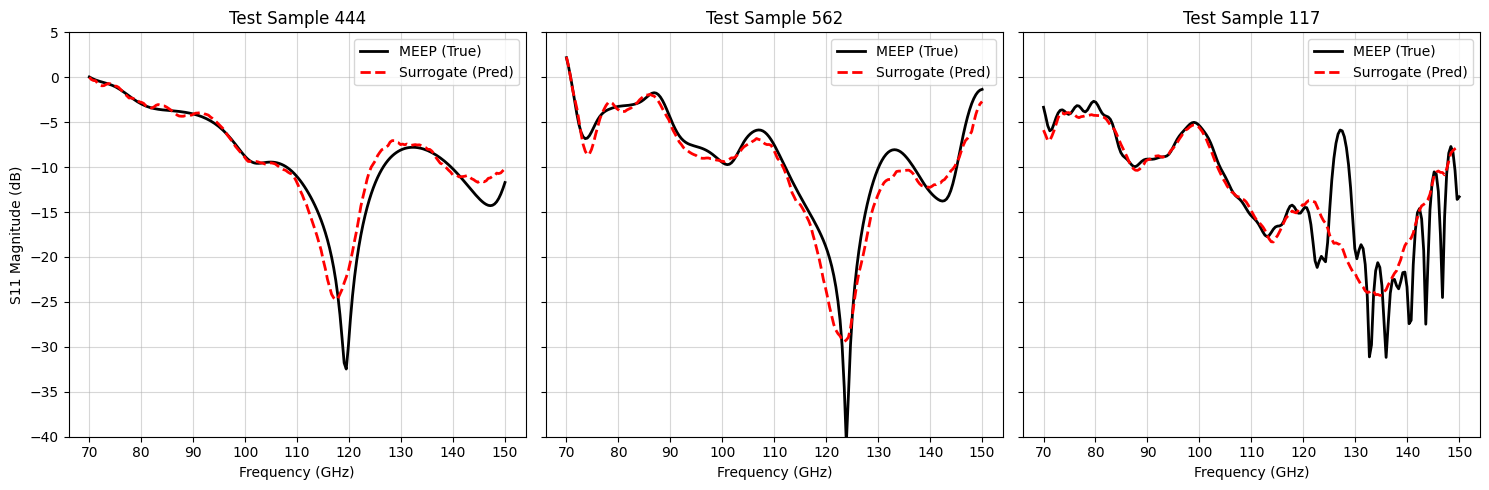

In [7]:
if __name__ == "__main__":
    print("1. Loading and splitting dataset...")
    train_loader, val_loader, test_loader, x_scaler, freqs, X_test, Y_test = load_and_preprocess(filename2)

    print("2. Initializing Bottleneck Surrogate Model...")
    model = BottleneckSurrogate(input_dim=7, latent_dim=32, output_dim=200)

    print("3. Commencing Training Loop...")
    train_loss, val_loss = train_model(model, train_loader, val_loader, epochs=500, lr=1e-3, patience=40)

    print("4. Evaluating Performance on Holdout Test Set...")
    evaluate_and_plot("best_surrogate_model.pth", X_test, Y_test, freqs)

### Paso 6: Algoritmo de diseño inverso y optimización evolutiva
Aquí definimos el marco de optimización para el diseño inverso utilizando algoritmos genéticos/evolutivos (`differential_evolution` de SciPy). Definimos una función objetivo que evalúa qué tan cerca está una geometría sugerida de cumplir con una plantilla de filtro objetivo (un perfil en 'V' de atenuación). El algoritmo utiliza nuestro modelo sustituto neuronal rápido para evaluar miles de combinaciones en segundos.

In [12]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import differential_evolution

def create_target_spectrum(freqs, center_freq, bandwidth, baseline=-3.0, target_depth=-30.0):
    """
    Dynamically creates a target S11 profile with a V-shaped notch.
    """
    target_s11 = np.full_like(freqs, baseline)

    half_bw = bandwidth / 2.0
    for i, f in enumerate(freqs):
        if center_freq - half_bw <= f <= center_freq + half_bw:
            # Calculate distance from the center frequency
            dist = abs(f - center_freq)
            # Linear interpolation to create a V-shape notch
            depth = target_depth + (baseline - target_depth) * (dist / half_bw)
            target_s11[i] = depth

    return target_s11

def optimize_filter(model, x_scaler, freqs, bounds, center_freq=90.0, bandwidth=5.0):
    """
    Runs the AI Inverse Design optimization to find the physical parameters
    that best match the desired center frequency and bandwidth.
    """
    # 1. Create the dynamic target
    target_s11 = create_target_spectrum(freqs, center_freq, bandwidth)

    # 2. Define the objective function (nested to access model/target locally)
    def objective_function(x):
        scaled_x = x_scaler.transform([x])
        tensor_input = torch.tensor(scaled_x, dtype=torch.float32)

        with torch.no_grad():
            pred_s11 = model(tensor_input).numpy().flatten()

        wband_mask = (freqs >= 75) & (freqs <= 150)
        pred_s11_wband = pred_s11[wband_mask]
        target_s11_wband = target_s11[wband_mask]


        pred_wband = pred_s11[wband_mask]
        target_wband = target_s11[wband_mask]
        freqs_wband = freqs[wband_mask]

        # Calculate base MSE
        squared_errors = (pred_wband - target_wband)**2

        # Apply a heavy weight (e.g., 50x) to the frequencies inside our desired notch
        notch_mask = (freqs_wband >= center_freq - bandwidth/2) & (freqs_wband <= center_freq + bandwidth/2)
        squared_errors[notch_mask] *= 50.0

        mse = np.mean(squared_errors)
        # Penalize physical impossibilities (> 0 dB)
        physics_penalty = np.sum(pred_s11_wband[pred_s11_wband > 0]) * 100

        return mse + physics_penalty

    # 3. Run Evolutionary Algorithm
    print(f"Optimizing for Center Freq: {center_freq} GHz, Bandwidth: {bandwidth} GHz...")
    result = differential_evolution(
        objective_function,
        bounds,
        strategy='best1bin',
        maxiter=50,
        popsize=15,
        tol=0.01,
        mutation=(0.5, 1.0),
        recombination=0.7
    )

    return result.x, target_s11



### Paso 7: Optimización del filtro para una banda de atenuación a 90 GHz
Iniciamos el proceso de diseño inverso para encontrar las dimensiones exactas de un filtro con un ancho de banda de $10\text{ GHz}$ centrado en $90\text{ GHz}$. Tras obtener los parámetros óptimos del optimizador, ejecutamos una simulación electromagnética completa (MEEP) para validar con alta precisión física los resultados predichos por la inteligencia artificial.

Optimizing for Center Freq: 90.0 GHz, Bandwidth: 10.0 GHz...



Optimization Complete!
Discovered Optimal Vector: [2.529 0.601 0.16  0.248 0.251 2.421 3.117]

Verifying discovered vector...


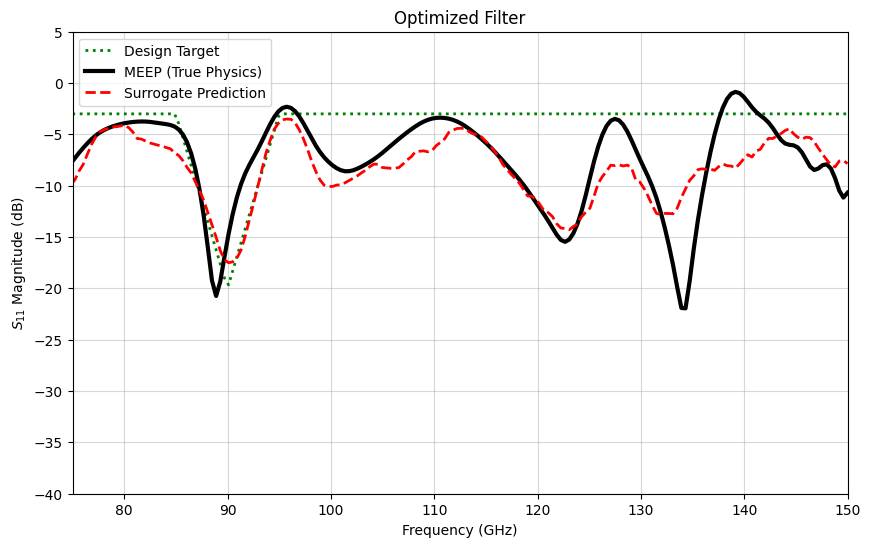

In [14]:
# ==========================================
# Execution / Usage Example
# ==========================================
if __name__ == "__main__":

    physical_bounds = list(PRIOR_BOUNDS.values())

    # Run the modular optimization
    optimal_vector, target_profile = optimize_filter(
        model=model,            # Your loaded PyTorch model
        x_scaler=x_scaler,      # Your fitted StandardScaler
        freqs=freqs,            # Frequency array from dataset
        bounds=physical_bounds,
        center_freq=90.0,       # Desired notch center
        bandwidth=10.0           # Desired bandwidth width
    )

    print("\nOptimization Complete!")
    print(f"Discovered Optimal Vector: {np.round(optimal_vector, 3)}")

    # Evaluate and Plot
    print("\nVerifying discovered vector...")

    # 1. Get the surrogate prediction for the optimal vector
    scaled_opt = x_scaler.transform([optimal_vector])
    with torch.no_grad():
        S11_Pred_opt = model(torch.tensor(scaled_opt, dtype=torch.float32)).numpy().flatten()

    # 2. Get Ground Truth from MEEP (Assuming you have evaluate_single_sample defined)
    _, S11_MEEP_opt, _, _ = evaluate_single_sample(optimal_vector)

    # Define the missing freqs_GHz variable
    freqs_GHz = freqs

    # 3. Plotting
    plt.figure(figsize=(10, 6))
    plt.plot(freqs, target_profile, 'g:', linewidth=2, label="Design Target")

    plt.plot(freqs_GHz, S11_MEEP_opt, 'k-', linewidth=3, label="MEEP (True Physics)")
    plt.plot(freqs, S11_Pred_opt, 'r--', linewidth=2, label="Surrogate Prediction")

    plt.title("Optimized Filter")
    plt.xlabel("Frequency (GHz)")
    plt.ylabel("$S_{11}$ Magnitude (dB)")

    # Updated plot bounds to visualize the full 75-150 GHz behavior
    plt.xlim(75, 150)
    plt.ylim(-40, 5)
    plt.grid(True, alpha=0.5)
    plt.legend()
    plt.show()

### Paso 8: Simulación de la propagación del campo electromagnético en régimen estacionario
Para ver en acción el dispositivo diseñado, configuramos una fuente de onda continua (CW) a la frecuencia exacta de resonancia de $90\text{ GHz}$. Simulamos la propagación del modo fundamental de la guía de ondas (TE10) a lo largo del tiempo y registramos los campos eléctricos para generar un video de la resonancia dentro del filtro.

/usr/local/lib/python3.13/site-packages/meep/visualization.py:1514: UserWarning: Warning: The 'sim' argument in Animate2D is deprecated and has no effect. It will be removed in a future release.
  warnings.warn(


Running simulation and generating animation for 90.0 GHz...


FloatProgress(value=0.0, description='0% done ', max=150.0)

Animation saved successfully as waveguide_90GHz_resonance.mp4


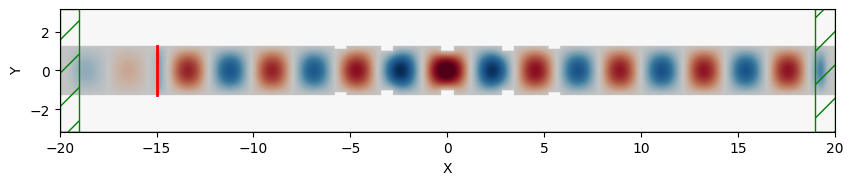

In [15]:
import meep as mp
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation

# 1. Physical Constants and Simulation Parameters
c_mm = 299.792458             # Speed of light in mm/ns
target_freq_GHz = 90.0        # Target frequency to visualize
fcen = target_freq_GHz / c_mm # MEEP frequency
resolution = 20               # Pixels per mm (keep moderate for fast animation)

# The vector that successfully created a passband near 90 GHz
params = optimal_vector
a, notch_width, h1, h2, h3, s1, s2 = params
heights = [h1, h2, h3, h2, h1]

# 2. Dynamic Geometry Layout
total_length = 2*s1 + 2*s2
start_x = -total_length / 2.0
x_positions = [
    start_x,
    start_x + s1,
    start_x + s1 + s2,
    start_x + s1 + s2 + s2,
    start_x + s1 + s2 + s2 + s1
]

# Expand the cell to give the wave room to establish and exit
cell_size = mp.Vector3(40, a * 2.5, 0) # Y is wider than 'a' to show the metal walls
pml_layers = [mp.PML(1.0, direction=mp.X)]

# Construct the waveguide walls and irises
geometry = [
    # Top and bottom solid waveguide walls
    mp.Block(size=mp.Vector3(mp.inf, (cell_size.y - a)/2, mp.inf),
             center=mp.Vector3(0, a/2 + (cell_size.y - a)/4, 0), material=mp.metal),
    mp.Block(size=mp.Vector3(mp.inf, (cell_size.y - a)/2, mp.inf),
             center=mp.Vector3(0, -a/2 - (cell_size.y - a)/4, 0), material=mp.metal)
]

# Add the internal irises
for i in range(5):
    h = heights[i]
    x_pos = x_positions[i]
    geometry.append(mp.Block(size=mp.Vector3(notch_width, h, mp.inf),
                             center=mp.Vector3(x_pos, a/2 - h/2, 0), material=mp.metal))
    geometry.append(mp.Block(size=mp.Vector3(notch_width, h, mp.inf),
                             center=mp.Vector3(x_pos, -a/2 + h/2, 0), material=mp.metal))

# 3. Continuous Wave Source
# Using a ContinuousSource instead of a Gaussian pulse to visualize steady-state resonance
sources = [mp.EigenModeSource(src=mp.ContinuousSource(frequency=fcen),
                              center=mp.Vector3(-15, 0, 0),
                              size=mp.Vector3(0, a, 0),
                              eig_band=1,
                              direction=mp.X)]

sim = mp.Simulation(cell_size=cell_size,
                    resolution=resolution,
                    boundary_layers=pml_layers,
                    sources=sources,
                    geometry=geometry)

# 4. Animation Setup
fig = plt.figure(figsize=(10, 4))

# Capture the out-of-plane electric field (Ez) which dictates the TE10 mode
animate = mp.Animate2D(sim, fields=mp.Ez, f=fig,
                       realtime=False, normalize=True,
                       field_parameters={'alpha': 0.8, 'cmap': 'RdBu'})

# 5. Run and Record
print(f"Running simulation and generating animation for {target_freq_GHz} GHz...")
# Run for 150 time units, taking a frame every 0.5 units
sim.run(mp.at_every(0.5, animate), until=150)

# 6. Save the Output
output_filename = "waveguide_90GHz_resonance.mp4"
animate.to_mp4(15, output_filename) # 15 frames per second
print(f"Animation saved successfully as {output_filename}")

### Paso 9: Visualización del video de resonancia y campos electromagnéticos
Finalmente, leemos el archivo de video generado (`waveguide_90GHz_resonance.mp4`), codificándolo en formato HTML5 para que puedas observar directamente en el cuaderno cómo interactúan las ondas con las paredes metálicas y cómo se genera el fenómeno de resonancia y filtrado.

In [17]:
from IPython.display import HTML
from base64 import b64encode

# Read the generated MP4 video file and display it inside the notebook
mp4_file = open('waveguide_90GHz_resonance.mp4', 'rb').read()
data_url = "data:video/mp4;base64," + b64encode(mp4_file).decode()

HTML(f"""
<video width="640" height="360" controls>
      <source src="{data_url}" type="video/mp4">
</video>
""")